In [17]:
#Very first step is to import these modules and libraries into the satprocessing kernel
import numpy as np
import dask as ds
import earthaccess as ea
import xarray as xr
import sys
import matplotlib.pyplot as plt
import requests
import pandas as pd
import PyCO2SYS as pyco2
import cartopy
from shapely.ops import unary_union
import cartopy.feature as cfeature
from datetime import date
from scipy.spatial import KDTree
from datasets import Dataset
print("module import success")

import sys
sys.path.append(r'C:\\Users\\edmund.gable\\Documents\\Hollings_2026\\RESOURCES\\python\\utilities\\bootstrap\\')
print("path import success")

import pprint
from environment import bootstrap_environment  
pprint.pprint(bootstrap_environment(preferred="edmund_gable"))
print("success")

from utilities.bootstrap.environment import bootstrap_environment
env = bootstrap_environment(preferred="edmund.gable")
env
print("utilities import success")

#Before this next step, install the library 'resource': conda install -c conda-forge resource
from utilities import get_dates, get_source_file_dates, find_text
find_text("stats")

from utilities import get_prod_files 
get_prod_files("DO", period="DOY")
#"DOY" is climatological 'day of year
#'W' is climatological weekly files

from pathlib import Path

root = Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026")
raw_data = Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data")
model_data = Path(r"Z:\\MOM6\Hindcasts\\BTM-O2-REGRID")
processed_data=Path(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\comparison")




module import success
path import success
⚠ Unrecognized preferred label 'edmund_gable'. Valid options: ['NECMAC04363461.local', 'nefscsatdata', 'guihyde', 'Mac.localdomain', 'gdavis', 'egable']
{'dataset_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/DATASETS'),
 'hostname': 'NECL04363598',
 'lookuptable_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/workflow_resources/lookuptables'),
 'metadata_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/workflow_resources/metadata'),
 'project_root': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/python'),
 'python_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/python'),
 'satlogs_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RESOURCES/logs/satprocessing'),
 'timestamp': datetime.datetime(2026, 6, 22, 8, 47, 42, 465889),
 'utilities_path': WindowsPath('C:/Users/edmund.gable/Documents/Hollings_2026/RES

In [18]:


def classify_DO(df, DO_column, status_col, battery_col=None):
    clean_df = df[df[DO_column] > 0].copy()
    classified_df = clean_df.copy()

    classified_df.loc[classified_df[DO_column] >= 3.9, status_col] = 'Low Oxygen'
    classified_df.loc[classified_df[DO_column] > 5.0, status_col] = 'Oxygenated' 
    classified_df.loc[classified_df[DO_column] < 3.9, status_col] = 'Mildly Hypoxic'
    classified_df.loc[classified_df[DO_column] < 2.41, status_col] = 'Hypoxia'
    classified_df.loc[classified_df[DO_column] < 0.2, status_col] = 'Anoxia'
      
    return classified_df
    
def open_file(file):
    ds = xr.open_dataset(file)
    df = ds.to_dataframe().reset_index()
    print("Available flattened columns:", df.columns.to_list())
    return df

def check_units(df, DO_col):
    # If checking pandas dataframe attributes instead of xarray dataset
    print(f"Checking units setup for column: {DO_col}")

In [35]:
def prepare_df(df, DO_col, id_col, obs_depth_col, bottom_depth_col, lat_col, lon_col, time_col, mom6_grid_df, battery_col=None):
    df = df.dropna(subset=[DO_col])

    depth_mismatch = abs(df[obs_depth_col] - df[bottom_depth_col]).astype(float)
    max_mismatch = np.minimum(0.1 * df[bottom_depth_col], 20)
    df_filtered = df[depth_mismatch < max_mismatch].copy()

    df_filtered["matched_time"] = pd.to_datetime(df_filtered[time_col]).dt.normalize() + pd.Timedelta(hours=12)
   
    pt_lats = xr.DataArray(df_filtered[lat_col], dims='points')
    pt_lons = xr.DataArray(df_filtered[lon_col], dims='points')

    nearest_grid = grid_ds.sel(lat=pt_lats, lon=pt_lons, method='nearest')

    df_filtered['matched_lat'] = nearest_grid.lat.values
    df_filtered['matched_lon'] = nearest_grid.lon.values
    df_filtered['grid_id'] = nearest_grid.grid_id.values.astype(str)
    df = df_filtered

    rename_dict = {
        DO_col: "dissolved_oxygen",
        id_col: "id",
        obs_depth_col: "obs_depth",
        bottom_depth_col: "bottom_depth",
        lat_col: "lat",
        lon_col: "lon",
        time_col: "time",
    }
    df = df.rename(columns=rename_dict)
    
    agg_rules = {
        "dissolved_oxygen": "mean",    
        "obs_depth": "mean",           
        "bottom_depth": "mean",        
        "lat": "mean",                 
        "lon": "mean",                 
        "id": "first",                 
        "matched_lat": "first",        
        "matched_lon": "first"         
    }
      
    df = df.groupby(['matched_time', 'grid_id'], as_index=False).agg(agg_rules)
    df = classify_DO(df, 'dissolved_oxygen', battery_col=battery_col)
    
    requested_columns = [
        "id", "lat", "lon", "obs_depth", "bottom_depth",
        "dissolved_oxygen", "DO_status", "grid_id",
        "matched_time", "matched_lat", "matched_lon"
    ]
    return df[requested_columns]


def prepare_df_no_depth(df, DO_col, id_col, lat_col, lon_col, time_col, mom6_grid_df, battery_col=None):
    df_filtered = df.dropna(subset=[DO_col]).copy()

    if battery_col is not None and battery_col in df_filtered.columns:
        df_filtered = df_filtered[df_filtered[battery_col] >= 50]
        
    df_filtered = df_filtered.reset_index(drop=True)
    df_filtered["matched_time"] = pd.to_datetime(df_filtered[time_col]).dt.normalize() + pd.Timedelta(hours=12)
     
    pt_lats = xr.DataArray(df_filtered[lat_col], dims='points')
    pt_lons = xr.DataArray(df_filtered[lon_col], dims='points')

    nearest_grid = grid_ds.sel(lat=pt_lats, lon=pt_lons, method='nearest')

    df_filtered['matched_lat'] = nearest_grid.lat.values
    df_filtered['matched_lon'] = nearest_grid.lon.values
    raw_ids = nearest_grid.grid_id.values.astype(str)
    
    # 2. Strip any negative signs and ensure a clean space after the separator
    clean_ids = [str(rid).replace('-', '') for rid in raw_ids]
    
    # 3. Save it to the dataframe
    df_filtered['grid_id'] = clean_ids
    # FIX: Cleaned up the assignment typo and converted cleanly to text string arrays
    df_filtered['grid_id'] = nearest_grid.grid_id.values.astype(str)

    rename_dict = {
        DO_col: "dissolved_oxygen",
        id_col: "id",
        lat_col: "lat",
        lon_col: "lon",
        time_col: "time",
    }
    df_mapped = df_filtered.rename(columns=rename_dict)
    
    agg_rules = {
        "dissolved_oxygen": "mean",     
        "lat": "mean",                  
        "lon": "mean",                  
        "id": "first",                  
        "matched_lat": "first",         
        "matched_lon": "first"          
    }
    
    # FIX: added as_index=False so pandas doesn't convert grid_id into a MultiIndex row layout
    df_agg = df_mapped.groupby(['matched_time', 'grid_id'], as_index=False).agg(agg_rules)
    df_classified = classify_DO(df_agg, 'dissolved_oxygen', battery_col=battery_col)
    
    requested_columns = [
        "id", "lat", "lon", "dissolved_oxygen", "DO_status",  
        "grid_id", "matched_time", "matched_lat", "matched_lon"
    ]
    return df_classified[requested_columns]

#Use this function to match mom6 data to observational data 
def load_matching_mom6_data(df, model_data):

    #load in a dataframe list to fill
    df_list = []

    # Get the list of unique datetimes from observational data
    unique_dates = pd.to_datetime(df['matched_time']).dt.normalize().unique()

    print(f"Found {len(unique_dates)} unique dates to query")

    #set the date structure
    for date in unique_dates:
        year = str(date.year)
        month = f"{date.month:02d}"
        day = f"{date.day:02d}"
        
        # Match the exact filename structure
        file_name = f"CEFI-BTM_O2-HINDCAST-{year}{month}{day}.nc"
        target_file_path = model_data / year / month / file_name
        
        # Filter the cruise dataframe down to just the points needed for this specific day
        current_date_str = f"{year}-{month}-{day}"
        df_day = df[pd.to_datetime(df['matched_time']).dt.normalize() == date]
        
        # Check if the file exists before attempting to open it
        if target_file_path.exists():
            print(f"Extracting data for {current_date_str}...")
            
            # Open the dataset
            ds = xr.open_dataset(target_file_path)
            
            # Extract ONLY the bottom oxygen variable
            o2_slice = ds['btm_o2'] 
            
            #  Target only the specific grid IDs present on this day ---
            for _, row in df_day.iterrows():
              try:
                    # Use coordinate matching (.sel) instead of positional indexing (.isel)
                    # This searches the grid using the target latitude and longitude directly
                    model_val = o2_slice.sel(
                        lat=row['matched_lat'], 
                        lon=row['matched_lon'], 
                        method='nearest'
                    ).values
                    
                    #  convert the resulting numpy array/scalar into a standard float
                    btm_o2_val = float(np.atleast_1d(model_val)[0])
              except Exception as e:
                    print(f" Lookup failed for Lat {row['matched_lat']}, Lon {row['matched_lon']}: {e}")
                    btm_o2_val = np.nan

                
                # Build a single clean row combining the cruise data with the model value
              matched_row = row.to_dict()
              matched_row['btm_o2'] = btm_o2_val
              df_list.append(matched_row)
            
            # Close the dataset file connection 
            ds.close()
        else:
            print(f"⚠️ Model file not found for {year}-{month}-{day} at: {target_file_path}")
            # If the file is missing, still retain the cruise data rows but fill model data with NaN
            for _, row in df_day.iterrows():
                matched_row = row.to_dict()
                matched_row['btm_o2'] = np.nan
                df_list.append(matched_row)

    # 4. Convert all individual rows into one single, master DataFrame
    if df_list:
        final_model_df = pd.DataFrame(df_list)
        return final_model_df
    else:
        print("No matching model files were found or loaded.")
        return pd.DataFrame() # Return empty dataframe as fallback
def delta_difference(df):
    # 1. Only calculate where model values exist
    df = df.dropna(subset=['closest_model_val']).copy()
    
    # 2. Calculate point-by-point delta difference
    df['delta_difference_point'] = df['exact_model_val'] - df['dissolved_oxygen']
    df['delta_difference_grid'] = df['closest_model_val'] - df['dissolved_oxygen']
    print(f"Mean of delta difference between model 3x3x3 grid data and observational data is: {np.nanmean(df['delta_difference_grid']):4f}")
    print(f"Mean of delta difference between model exact grid data and observational data is: {np.nanmean(df['delta_difference_point']):4f}")
    # 3. Calculate Global Dataset RMSE
    # RMSE is the square root of the mean of squared differences between model and observations
    global_rmse_grid = np.sqrt(np.nanmean(df['delta_difference_grid'] ** 2))
    print(f"Global RMSE (3x3x3 grid vs obs) between model and observations is: {global_rmse_grid:.4f}")
    
# Exact Match RMSE (Slices down to only where valid exact pairs exist)
    valid_exact = df.dropna(subset=['delta_difference_point'])
    global_rmse_exact = np.sqrt((valid_exact['delta_difference_point'] ** 2).mean())
    print(f"Global RMSE (Exact point vs Obs): {global_rmse_exact:.4f}")
    print(f"-> Calculated using {len(valid_exact)} valid exact points (out of {len(df)} total pairs).")

    # 4. Calculate Local Z-score (point relative to its 3x3x3 grid)
    # Note: Added 1e-9 to prevent division-by-zero if a cube std is 0 
    df['local_z_score'] = (df['cube_mean'] - df['dissolved_oxygen']) / (df['cube_std'] + 1e-9)
    
    # 5. Calculate Global Statistics using Grand Variance formulas (assuming N=27 for each grid)
    global_mean = df['cube_mean'].mean()
    obs_mean=df['dissolved_oxygen'].mean()
    
    # Combined variance formula: mean of variances + variance of means
    mean_of_variance=(df['cube_std']**2).mean()
    variance_of_means=df['cube_mean'].var()

    global_variance = mean_of_variance + variance_of_means
    global_std = np.sqrt(global_variance)
    
    print(f"Calculated Observational Mean: {obs_mean:.4f}")
    print(f"Calculated Model Global Mean: {global_mean:.4f}")
    print(f"Calculated Global Std Dev: {global_std:.4f}")
    over_est_pct=(df['delta_difference_grid']>0).mean()*100
    under_est_pct=(df['delta_difference_grid']<0).mean()*100
    print(f"Model grid overestimates the data {over_est_pct} percent of the time")
    print(f"Model grid underestimates the data {under_est_pct} percent of the time")
    avg_overestimation = df[df['delta_difference_grid'] > 0]['delta_difference_grid'].mean()
    avg_underestimation = df[df['delta_difference_grid'] < 0]['delta_difference_grid'].mean()

    print(f"When overestimating, the average excess oxygen is: {avg_overestimation:.4f}")
    print(f"When underestimating, the average deficit oxygen is: {avg_underestimation:.4f}")

    # Calculate the standard deviation of your real-world observations
    obs_std = df['dissolved_oxygen'].std()

    print(f"Real-World Observational STD: {obs_std:.4f}")
    print(f"Model Global STD: {global_std:.4f}")

# Compare them
    std_ratio = global_std / obs_std
    print(f"Model-to-Observation Variance Ratio: {std_ratio:.2f}")
    
    # 6. Calculate Global Z-score for each observational point
    df['global_z_score'] = (df['dissolved_oxygen'] - global_mean) / global_std
    
    
    stressed_obs = df[df['DO_status'] != 'Oxygenated']
    stressed_mod=df[df['model_DO_status'] != 'Oxygenated']
    
    if len(stressed_obs) > 0:
        # 2. Calculate how often the model status matches the observation status exactly
        status_matches = (stressed_obs['DO_status'] == stressed_obs['model_DO_status']).sum()
        match_rate = (status_matches / len(stressed_obs)) * 100
        false_positive = ((df['model_DO_status'] != 'Oxygenated') & (df['model_DO_status'] != df['DO_status'])).sum()
        false_negative = ((df['model_DO_status'] == 'Oxygenated') & (df['model_DO_status'] != df['DO_status'])).sum()
        #mod_len = len(stressed_mod) if len(stressed_mod) > 0 else 1
        fpp=(false_positive / len(stressed_mod))*100
        fnp=(false_negative / len(stressed_obs))*100
        
        print(f"\n===========================================================")
        print(f"OXYGEN STATUS MATCH METRICS (Excluding 'oxygenated')")
        print(f"===========================================================")
        print(f"Total observations showing stressed conditions: {len(stressed_obs)}")
        print(f"Total model outputs showing stressed conditions: {len(stressed_mod)}")
        print(f'False Positives: Of the {len(stressed_mod)} times the model predicted stress, {fpp:.2f}% were false alarms')
        print(f'False Negatives: Of the {len(stressed_obs)} times the observations detected stress, {fnp:.2f}% were missed by the model')
        print(f"Overall Model Match Accuracy: {match_rate:.2f}%")
        print(f"-----------------------------------------------------------")
    return df

In [20]:
def load_3x3x3_MOM6(df, model_data, mom6_var='btm_o2'):
    model_data = Path(model_data)
    df_list = []

    df = df.copy()
    df['matched_time'] = pd.to_datetime(df['matched_time'])
    unique_dates = df['matched_time'].dt.normalize().unique()

    print(f"Found {len(unique_dates)} unique dates to query.")

    for center_date in unique_dates:
        t_minus = center_date - pd.Timedelta(days=1)
        t_plus  = center_date + pd.Timedelta(days=1)
        target_days = [t_minus, center_date, t_plus]
        
        daily_slices = []

        for d in target_days:
            year = str(d.year)
            month = f"{d.month:02d}"
            day = f"{d.day:02d}"
            
            file_name = f"CEFI-BTM_O2-HINDCAST-{year}{month}{day}.nc"
            target_file_path = model_data / year / month / file_name

            if target_file_path.exists():
                ds = xr.open_dataset(target_file_path)
                o2_converted = ds[mom6_var] * 31998.8 * 1.025
                daily_slices.append(o2_converted)
                ds.close()
                    
        if not daily_slices:
            continue

        print(f"Extracting 3x3x3 space-time matrix for {center_date.strftime('%Y-%m-%d')}...")
        df_day = df[df['matched_time'].dt.normalize() == center_date]

        ds_window = xr.concat(daily_slices, dim='time')
        
        # FIX: Align the daily window map directly to the master template coordinates
        ds_window = ds_window.assign_coords(grid_id=(['lat', 'lon'], grid_ds.grid_id.values))
        ds_window['grid_id'] = ds_window['grid_id'].astype(str)

        lat_arr = ds_window.lat.values
        lon_arr = ds_window.lon.values

        for idx, row in df_day.iterrows():
            lat_idx = int(np.argmin(np.abs(lat_arr - row['lat'])))
            lon_idx = int(np.argmin(np.abs(lon_arr - row['lon'])))
            
            lat_slice = slice(max(0, lat_idx - 1), lat_idx + 2)
            lon_slice = slice(max(0, lon_idx - 1), lon_idx + 2)
            
            cube_3x3x3 = ds_window.isel(lat=lat_slice, lon=lon_slice)
            o2_cube = cube_3x3x3.values 
            
            if np.all(np.isnan(o2_cube)):
                continue

            #calculate the mean, std, min and max of the cube values
            mean_o2 = float(np.nanmean(o2_cube))
            std_o2  = float(np.nanstd(o2_cube))
            min_o2  = float(np.nanmin(o2_cube))
            max_o2  = float(np.nanmax(o2_cube))

            abs_diff = np.abs(o2_cube - row['dissolved_oxygen'])
            flat_idx = np.nanargmin(abs_diff) 
            grid_t, grid_y, grid_x = np.unravel_index(flat_idx, o2_cube.shape)

            closest_val  = float(o2_cube[grid_t, grid_y, grid_x])
            closest_lat  = float(cube_3x3x3.lat.values[grid_y])
            closest_lon  = float(cube_3x3x3.lon.values[grid_x])
            closest_time = pd.Timestamp(cube_3x3x3.time.values[grid_t])

            #  Safely retrieve the true string index coordinates without negative offsets
            if 'grid_id' in cube_3x3x3.coords:
                # 1. Grab the raw string value and strip any minus signs
                text = str(cube_3x3x3.grid_id.values[grid_y, grid_x]).replace('-', '')
                
                # 2. Split normally (Y first, then X) to match your grid_id layout
                sep = ';' if ';' in text else ','
                y_val, x_val = text.split(sep)
                
                # 3. Wrap it in parentheses with the clean space
                closest_grid_id = f"({y_val.strip()}{sep} {x_val.strip()})"
            else:
                closest_grid_id = f"({closest_lat}, {closest_lon})"

            matched_row = row.to_dict()
            matched_row.update({
                "cube_mean": mean_o2,
                "cube_std": std_o2,
                "cube_min": min_o2,
                "cube_max": max_o2,
                "closest_model_val": closest_val,
                "closest_grid_id": closest_grid_id,
                "closest_lat": closest_lat,
                "closest_lon": closest_lon,
                "closest_time": closest_time
            })
            df_list.append(matched_row)

    return pd.DataFrame(df_list).reset_index(drop=True)

In [21]:
#do both grid and exact at once

def load_combined_mom6_data(df, model_data, mom6_var='btm_o2', grid_ds=None):
    model_data = Path(model_data)
    df_list = []
    
    df = df.copy()
    df['matched_time'] = pd.to_datetime(df['matched_time'])
    unique_dates = df['matched_time'].dt.normalize().unique()
    
    print(f"Processing {len(unique_dates)} unique dates...")
    
    for center_date in unique_dates:
        # 1. Load the 3-day window around the center date
        target_days = [center_date - pd.Timedelta(days=1), center_date, center_date + pd.Timedelta(days=1)]
        daily_slices = []
        
        for d in target_days:
            file_name = f"CEFI-BTM_O2-HINDCAST-{d.year}{d.month:02d}{d.day:02d}.nc"
            target_file_path = model_data / f"{d.year}" / f"{d.month:02d}" / file_name
            
            if target_file_path.exists():
                with xr.open_dataset(target_file_path) as ds:
                    # Apply unit conversion uniformly if needed
                    o2_converted = ds[mom6_var] * 31998.8 * 1.025
                    daily_slices.append(o2_converted.load()) # Load to memory for performance
                    
        if not daily_slices:
            continue
            
        ds_window = xr.concat(daily_slices, dim='time')
        if grid_ds is not None:
            ds_window = ds_window.assign_coords(grid_id=(['lat', 'lon'], grid_ds.grid_id.values))
            ds_window['grid_id'] = ds_window['grid_id'].astype(str)
            
        lat_arr, lon_arr = ds_window.lat.values, ds_window.lon.values
        df_day = df[df['matched_time'].dt.normalize() == center_date]
        
        # 2. Extract space-time metrics for each observation point on this day
        for idx, row in df_day.iterrows():
            # Find closest center indices
            lat_idx = int(np.argmin(np.abs(lat_arr - row['lat'])))
            lon_idx = int(np.argmin(np.abs(lon_arr - row['lon'])))
            
            # Slice out the 3x3 horizontal window
            lat_slice = slice(max(0, lat_idx - 1), lat_idx + 2)
            lon_slice = slice(max(0, lon_idx - 1), lon_idx + 2)
            cube_3x3x3 = ds_window.isel(lat=lat_slice, lon=lon_slice)
            o2_cube = cube_3x3x3.values 
            
            if np.all(np.isnan(o2_cube)):
                continue
                
            # --- EXACT SPATIOTEMPORAL MATCH ---
            # Index exact center (Time=center_date, and center cell of our slice)
            t_exact_idx = np.where(pd.to_datetime(cube_3x3x3.time.values).date == center_date.date())[0][0]
            y_exact_idx = int(np.argmin(np.abs(cube_3x3x3.lat.values - row['lat'])))
            x_exact_idx = int(np.argmin(np.abs(cube_3x3x3.lon.values - row['lon'])))
            exact_match_val = float(o2_cube[t_exact_idx, y_exact_idx, x_exact_idx])

            # --- CLOSEST 3x3x3 NEIGHBOR MATCH ---
            abs_diff = np.abs(o2_cube - row['dissolved_oxygen'])
            flat_idx = np.nanargmin(abs_diff) 
            grid_t, grid_y, grid_x = np.unravel_index(flat_idx, o2_cube.shape)
            
            closest_val = float(o2_cube[grid_t, grid_y, grid_x])
            closest_lat = float(cube_3x3x3.lat.values[grid_y])
            closest_lon = float(cube_3x3x3.lon.values[grid_x])
            closest_time = pd.Timestamp(cube_3x3x3.time.values[grid_t])
            
            # Extract Grid ID
            if 'grid_id' in cube_3x3x3.coords:
                text = str(cube_3x3x3.grid_id.values[grid_y, grid_x]).replace('-', '')
                sep = ';' if ';' in text else ','
                y_val, x_val = text.split(sep)
                closest_grid_id = f"({y_val.strip()}{sep} {x_val.strip()})"
            else:
                closest_grid_id = f"({closest_lat}, {closest_lon})"
                
            # --- MERGE INTO DATA DICTIONARY ---
            matched_row = row.to_dict()
            matched_row.update({
                "exact_model_val": exact_match_val,
                "cube_mean": float(np.nanmean(o2_cube)),
                "cube_std": float(np.nanstd(o2_cube)),
                "cube_min": float(np.nanmin(o2_cube)),
                "cube_max": float(np.nanmax(o2_cube)),
                "closest_model_val": closest_val,
                "closest_grid_id": closest_grid_id,
                "closest_lat": closest_lat,
                "closest_lon": closest_lon,
                "closest_time": closest_time
            })
            df_list.append(matched_row)
            
    return pd.DataFrame(df_list).reset_index(drop=True)

In [22]:
# 1. Establish the Master Blueprint Grid Layout
dsg = xr.open_dataset(r"Z:\MOM6\Hindcasts\BTM-O2-REGRID\2005\03\CEFI-BTM_O2-HINDCAST-20050321.nc")
ny, nx = len(dsg.lat), len(dsg.lon)
grid_id_matrix = np.array([[f"{y},{x}" for x in range(nx)] for y in range(ny)], dtype=str)
grid_ds = dsg.assign_coords(grid_id=(['lat', 'lon'], grid_id_matrix))

In [22]:

# 2. Extract Observational Fields
file = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\eMOLT\eMOLT_2000_2026.nc"
df = open_file(file)
check_units(df, 'DO')

# 3. Read Extent Settings
mom6_grid_df = pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Index\MOM6_Grid_Extent.csv")

# 4. Generate the Prepared Dataframe
dfp = prepare_df_no_depth(df, 'DO', 'tow_id', 'latitude', 'longitude', 'time', mom6_grid_df, 'water_detect_perc')


dfp.to_csv(processed_data /  "eMOLT_MOM6_grid_matched.csv")

print("Export Complete! Data successfully compiled.")

Available flattened columns: ['row', 'tow_id', 'time', 'latitude', 'longitude', 'temperature', 'DO', 'DO_percentage', 'water_detect_perc', 'sensor_type']
Checking units setup for column: DO
Export Complete! Data successfully compiled.


In [41]:
# Load your observational csv
dfp = pd.read_csv(processed_data / "eMOLT_MOM6_grid_matched.csv")

# Run the query function
#eMOLT = load_3x3x3_MOM6(dfp, model_data, mom6_var='btm_o2')
eMOLT=load_combined_mom6_data(dfp, model_data, mom6_var='btm_o2', grid_ds=grid_ds)


Processing 692 unique dates...


In [52]:
final=delta_difference(eMOLT)
final.to_csv(processed_data  / 'eMOLT_MOM6_3x3x3_comparison.csv')
final

Mean of delta difference between model 3x3x3 grid data and observational data is: 2.371695
Mean of delta difference between model exact grid data and observational data is: 2.708532
Global RMSE (3x3x3 grid vs obs) between model and observations is: 2.8602
Global RMSE (Exact point vs Obs): 3.1046
-> Calculated using 293 valid exact points (out of 369 total pairs).
Calculated Observational Mean: 6.2342
Calculated Model Global Mean: 8.7650
Calculated Global Std Dev: 0.6551
Model grid overestimates the data 90.2439024390244 percent of the time
Model grid underestimates the data 9.75609756097561 percent of the time
When overestimating, the average excess oxygen is: 2.7715
When underestimating, the average deficit oxygen is: -1.3261


,Unnamed: 0,id,lat,lon,dissolved_oxygen,DO_status,grid_id,matched_time,matched_lat,matched_lon,...,cube_max,closest_model_val,closest_grid_id,closest_lat,closest_lon,closest_time,delta_difference_point,delta_difference_grid,local_z_score,global_z_score
0,0,4497.0,41.771200,-70.50370,6.676296,Oxygenated,"307,148",2023-07-31 12:00:00,41.786113,-70.528487,...,9.606815,9.563205,"(308, 149)",41.848851,-70.447812,2023-07-31 12:00:00,NaN,2.886909,162.859321,-3.188204
1,1,4316.0,41.831300,-70.45170,6.770303,Oxygenated,"308,149",2023-07-31 12:00:00,41.848851,-70.447812,...,9.797547,9.484906,"(308, 150)",41.848851,-70.367136,2023-07-31 12:00:00,2.792902,2.714603,24.360097,-3.044715
2,2,4361.0,41.850395,-70.37824,5.688809,Oxygenated,"308,150",2023-07-31 12:00:00,41.848851,-70.367136,...,9.797547,9.484906,"(308, 150)",41.848851,-70.367136,2023-07-31 12:00:00,3.796097,3.796097,33.573511,-4.695477
3,3,4497.0,41.771200,-70.50370,6.307500,Oxygenated,"307,148",2023-08-01 12:00:00,41.786113,-70.528487,...,9.593822,9.563205,"(308, 149)",41.848851,-70.447812,2023-07-31 12:00:00,NaN,3.255704,259.341572,-3.751124
4,4,4316.0,41.831300,-70.45170,6.312084,Oxygenated,"308,149",2023-08-01 12:00:00,41.848851,-70.447812,...,9.795568,9.484379,"(308, 150)",41.848851,-70.367136,2023-08-02 12:00:00,3.270079,3.172295,26.539787,-3.744128
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
364,367,4358.0,41.825100,-70.44100,11.482500,Oxygenated,"308,149",2023-11-11 12:00:00,41.848851,-70.447812,...,8.220432,8.220432,"(308, 150)",41.848851,-70.367136,2023-11-12 12:00:00,-3.468020,-3.262068,-36.053726,4.147854
365,368,4397.0,41.850550,-70.40325,9.378646,Oxygenated,"308,150",2023-11-11 12:00:00,41.848851,-70.367136,...,8.579047,8.579047,"(308, 151)",41.848851,-70.286460,2023-11-12 12:00:00,-1.419890,-0.799599,-7.528834,0.936589
366,369,4397.0,41.850550,-70.40325,10.627708,Oxygenated,"308,150",2023-11-12 12:00:00,41.848851,-70.367136,...,8.612222,8.612222,"(308, 151)",41.848851,-70.286460,2023-11-13 12:00:00,-2.407276,-2.015486,-11.294403,2.843123
367,370,4397.0,41.850628,-70.40295,9.980397,Oxygenated,"308,150",2023-11-13 12:00:00,41.848851,-70.367136,...,8.634256,8.634256,"(308, 151)",41.848851,-70.286460,2023-11-14 12:00:00,-1.540164,-1.346141,-7.271055,1.855085


For ECOMON

In [8]:

# 1. Extract Observational Fields
file = r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Raw_Data\Hydrographic_Monitoring\errdap_search.nc"
df = open_file(file)
check_units(df, 'dissolved_oxygen')

# 3. Read Extent Settings
mom6_grid_df = pd.read_csv(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Index\MOM6_Grid_Extent.csv")

# 4. Generate the Prepared Dataframe
dfp = prepare_df(df, 'dissolved_oxygen', 'cruise_id', 'depth', 'bottom_depth', 'latitude', 'longitude', 'UTC_DATETIME', mom6_grid_df)


dfp.to_csv(processed_data /  "ECOMON_MOM6_grid_matched.csv")

print("Export Complete! Data successfully compiled.")

Available flattened columns: ['row', 'UTC_DATETIME', 'latitude', 'longitude', 'depth', 'dissolved_oxygen', 'cruise_id', 'purpose_code', 'bottom_depth', 'GEAR_TYPE']
Checking units setup for column: dissolved_oxygen
Export Complete! Data successfully compiled.


In [9]:
ECOMON=load_combined_mom6_data(dfp, model_data, mom6_var='btm_o2', grid_ds=grid_ds)
ECOMON.to_csv(processed_data / 'ECOMON_MOM6_3x3x3_prepped.csv')

Processing 1258 unique dates...


In [36]:
df=pd.read_csv(processed_data / 'ECOMON_MOM6_3x3x3_prepped.csv')
df=df[df['id']!='HB2101'] #removed this cruise because the oxygen detector malfunctioned
final=classify_DO(df, 'closest_model_val', 'model_DO_status', battery_col=None)
print(final.columns.to_list())
final= delta_difference(final)


['Unnamed: 0', 'id', 'lat', 'lon', 'obs_depth', 'bottom_depth', 'dissolved_oxygen', 'DO_status', 'grid_id', 'matched_time', 'matched_lat', 'matched_lon', 'exact_model_val', 'cube_mean', 'cube_std', 'cube_min', 'cube_max', 'closest_model_val', 'closest_grid_id', 'closest_lat', 'closest_lon', 'closest_time', 'model_DO_status']
Mean of delta difference between model 3x3x3 grid data and observational data is: 0.372079
Mean of delta difference between model exact grid data and observational data is: 0.417980
Global RMSE (3x3x3 grid vs obs) between model and observations is: 0.9462
Global RMSE (Exact point vs Obs): 1.2622
-> Calculated using 3963 valid exact points (out of 3972 total pairs).
Calculated Observational Mean: 6.8572
Calculated Model Global Mean: 7.3509
Calculated Global Std Dev: 1.3734
Model grid overestimates the data 67.14501510574019 percent of the time
Model grid underestimates the data 32.85498489425982 percent of the time
When overestimating, the average excess oxygen is: 

In [47]:
final.to_csv(processed_data / 'ECOMON_MOM6_3x3x3_comparison.csv')

<>:42: SyntaxWarning: invalid escape sequence '\D'
<>:43: SyntaxWarning: invalid escape sequence '\D'
<>:44: SyntaxWarning: invalid escape sequence '\m'
<>:45: SyntaxWarning: invalid escape sequence '\m'
<>:46: SyntaxWarning: invalid escape sequence '\s'
<>:42: SyntaxWarning: invalid escape sequence '\D'
<>:43: SyntaxWarning: invalid escape sequence '\D'
<>:44: SyntaxWarning: invalid escape sequence '\m'
<>:45: SyntaxWarning: invalid escape sequence '\m'
<>:46: SyntaxWarning: invalid escape sequence '\s'
C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_9412\1976975554.py:42: SyntaxWarning: invalid escape sequence '\D'
  f"Mean $\Delta$: {mean_delta:+.3f} mg/L\n"
C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_9412\1976975554.py:43: SyntaxWarning: invalid escape sequence '\D'
  f"Median $\Delta$: {median_delta:+.3f} mg/L\n"
C:\Users\edmund.gable\AppData\Local\Temp\ipykernel_9412\1976975554.py:44: SyntaxWarning: invalid escape sequence '\m'
  f"Model $\mu$: {global_mean:.3f} mg/L\n"

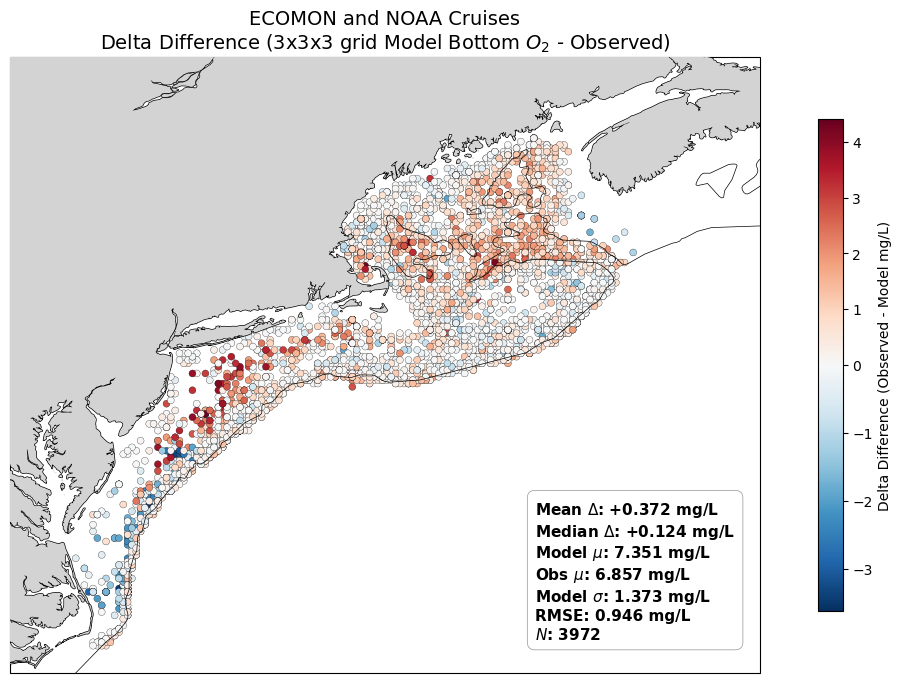

In [37]:
import matplotlib.colors as mcolors

bathym = cfeature.NaturalEarthFeature(name='bathymetry_K_200', scale='10m', category='physical')
bathym = unary_union(list(bathym.geometries()))

fig = plt.figure(figsize=(15, 8)) #set figure size
map_projection = cartopy.crs.PlateCarree() #set map projection
ax = plt.axes(projection=map_projection) #link projection to axes
sc=ax.scatter(final['matched_lon'].astype(float), final['matched_lat'].astype(float), c=final['delta_difference'], cmap='RdBu_r', s=25, edgecolors='black', linewidths=0.2, transform=cartopy.crs.PlateCarree())

cb = plt.colorbar(sc, shrink=0.8, label='Delta Difference (Observed - Model mg/L)')

# Optional: Center the colorbar around 0 if you want to balance over/underestimation
# import matplotlib.colors as mcolors
sc.set_norm(mcolors.TwoSlopeNorm(vcenter=0))

# 5. Add map layers and features
ax.add_feature(cfeature.COASTLINE, linewidth=1)
ax.add_feature(cfeature.LAND, zorder=100, facecolor='lightgrey')
ax.add_geometries(bathym, facecolor='none', edgecolor='black', linewidth=0.5, crs=cartopy.crs.PlateCarree())

# 6. Set map spatial limits (Mid-Atlantic Bight / New England shelf)
ax.set_extent([-77, -63, 34.5, 46])

# 7. Add text decoration
ax.set_title('ECOMON and NOAA Cruises\nDelta Difference (3x3x3 grid Model Bottom $O_2$ - Observed)', fontsize=14)

#8. Add text to display mean average
# 1. Calculate the stats cleanly 
mean_delta = final['delta_difference'].mean()
median_delta = final['delta_difference'].median()  
total_pts = len(final['delta_difference'].dropna())
global_mean = df['cube_mean'].mean()
obs_mean=df['dissolved_oxygen'].mean()
global_variance = (df['cube_std']**2).mean() + df['cube_mean'].var()
global_std = np.sqrt(global_variance)
global_rmse = np.sqrt((final['delta_difference'] ** 2).mean())
    

# 2. Format the display string 
text_str = (
    f"Mean $\Delta$: {mean_delta:+.3f} mg/L\n"
    f"Median $\Delta$: {median_delta:+.3f} mg/L\n"
    f"Model $\mu$: {global_mean:.3f} mg/L\n"
    f"Obs $\mu$: {obs_mean:.3f} mg/L\n"
    f"Model $\sigma$: {global_std:.3f} mg/L\n"
    f"RMSE: {global_rmse:.3f} mg/L\n"
    f"$N$: {total_pts}"
)

# 3. Define the bounding box style (semi-transparent white block)
box_style = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='gray', linewidth=0.5)

# 4. Place the text box in the lower-right quadrant of the axes view
ax.text(
    0.7, 0.05,                   # Coordinates (x=97% right, y=5% up from bottom)
    text_str, 
    transform=ax.transAxes,       # Lock placement to screen space
    fontsize=11, 
    fontweight='bold',
    va='bottom', 
    ha='left', 
    bbox=box_style,
    zorder=105                    # Sits cleanly on top of gray landmasses
)
# =====================================================================
plt.show()

start breaking down by year, season
break down delta differences by region

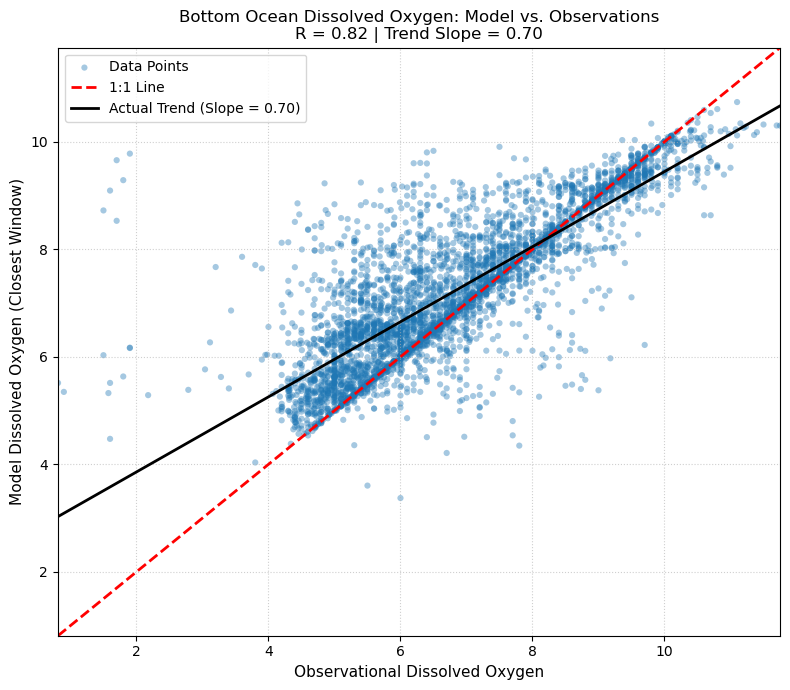

In [26]:
import matplotlib.pyplot as plt
import numpy as np

def plot_model_vs_obs_with_trend(df):
    # Drop NaNs to ensure clean plotting and calculations
    plot_df = df.dropna(subset=['dissolved_oxygen', 'closest_model_val']).copy()
    
    x_data = plot_df['dissolved_oxygen']
    y_data = plot_df['closest_model_val']
    
    plt.figure(figsize=(8, 7))
    
    # 1. Core Scatter plot
    plt.scatter(
        x_data, 
        y_data, 
        s=20, 
        color='#1f77b4', 
        alpha=0.4, 
        edgecolors='none', 
        label='Data Points'
    )
    
    # 2. Dynamic 1:1 Line of Perfect Agreement
    min_val = min(x_data.min(), y_data.min())
    max_val = max(x_data.max(), y_data.max())
    plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='1:1 Line')
    
    # 3. Calculate and Plot the ACTUAL Linear Relationship Line
    # np.polyfit calculates the slope (m) and intercept (c) for y = mx + c
    slope, intercept = np.polyfit(x_data, y_data, 1)
    x_trend = np.linspace(min_val, max_val, 100)
    y_trend = slope * x_trend + intercept
    
    plt.plot(
        x_trend, 
        y_trend, 
        color='black', 
        linestyle='-', 
        linewidth=2, 
        label=f'Actual Trend (Slope = {slope:.2f})'
    )
    
    # 4. Calculate Pearson Correlation (R)
    r_val = x_data.corr(y_data)
    
    # 5. Formatting
    plt.title(f"Bottom Ocean Dissolved Oxygen: Model vs. Observations\nR = {r_val:.2f} | Trend Slope = {slope:.2f}", fontsize=12)
    plt.xlabel("Observational Dissolved Oxygen", fontsize=11)
    plt.ylabel("Model Dissolved Oxygen (Closest Window)", fontsize=11)
    
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)
    plt.legend(loc='upper left')
    plt.grid(True, linestyle=':', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

# Call the function
plot_model_vs_obs_with_trend(eMOLT)

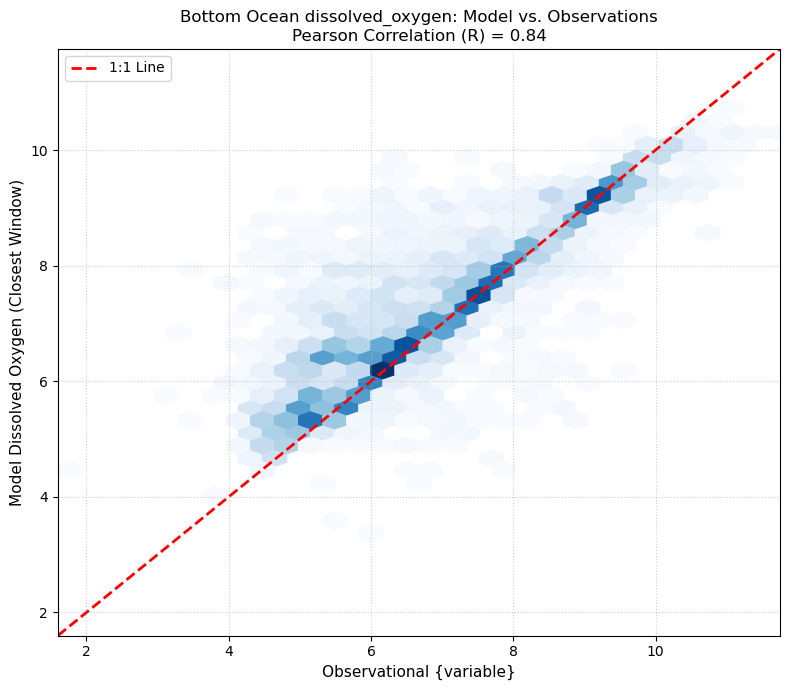

In [22]:
import matplotlib.pyplot as plt
import numpy as np

def plot_model_vs_obs(df, variable):
    # Drop NaNs to ensure clean plotting
    plot_df = df.dropna(subset=[variable, 'closest_model_val']).copy()
    
    x_data = plot_df[variable]
    y_data = plot_df['closest_model_val']
    
    plt.figure(figsize=(8, 7))
    
    # 1. Core Matplotlib scatter plot
    # s=20 sets point size, alpha=0.5 handles overlapping data points beautifully
    plt.hexbin(x_data, y_data, gridsize=30, cmap='Blues', mincnt=1)
    
    # 2. Dynamic 1:1 Line of Perfect Agreement
    min_val = min(x_data.min(), y_data.min())
    max_val = max(x_data.max(), y_data.max())
    plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='1:1 Line')
    
    # 3. Calculate Pearson Correlation (R)
    r_val = x_data.corr(y_data)
    
    # 4. Formatting
    plt.title(f"Bottom Ocean {variable}: Model vs. Observations\nPearson Correlation (R) = {r_val:.2f}", fontsize=12)
    plt.xlabel("Observational {variable}", fontsize=11)
    plt.ylabel("Model Dissolved Oxygen (Closest Window)", fontsize=11)
    
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)
    plt.legend(loc='upper left')
    plt.grid(True, linestyle=':', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

# Call the function
plot_model_vs_obs(final, 'dissolved_oxygen')

In [16]:
df=pd.read_excel(r"C:\Users\edmund.gable\Documents\Hollings_2026\GitHub\MOM6-COBALT_2026\data\Processed_Data\Fishbot_Hypoxia.xlsx")
df=df.dropna(subset=['dissolved_oxygen'])
providers_to_exclude = ['ECOMON', 'eMOLT', 'eMOLT, ECOMON', 'eMOLT, OOI']


df = df[~df['data_provider'].isin(providers_to_exclude)]
df.to_csv(processed_data / 'Fishbot_removed_ECOMON+eMOLT.csv')